In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load California Housing Dataset
housing = fetch_california_housing(as_frame=True)

# Convert into DataFrame
df = housing.frame

print("Dataset loaded successfully!")
print("Dataset Name: California Housing Dataset")
print("Source: Scikit-learn / StatLib California Housing Dataset")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Name: California Housing Dataset
Source: Scikit-learn / StatLib California Housing Dataset
Dataset Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Display first 5 records
print("First 5 Records:")
display(df.head())

# Display last 5 records
print("Last 5 Records:")
display(df.tail())

# Dataset information
print("Dataset Information:")
df.info()

# Statistical summary
print("Statistical Summary:")
display(df.describe())

# Column names
print("Column Names:")
print(df.columns.tolist())

First 5 Records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Last 5 Records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Handle missing values if present
df = df.dropna()

# Remove duplicate records if present
df = df.drop_duplicates()

print("\nAfter Data Cleaning:")
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Rows:", df.duplicated().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Records:
0

After Data Cleaning:
Dataset Shape: (20640, 9)
Total Missing Values: 0
Total Duplicate Rows: 0


In [5]:
# Independent variable (Input)
X = df[['MedInc']]

# Dependent variable (Target)
y = df['MedHouseVal']

print("Input Feature: MedInc")
print("Target Feature: MedHouseVal")

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature: MedInc
Target Feature: MedHouseVal

Input Shape: (20640, 1)
Target Shape: (20640,)


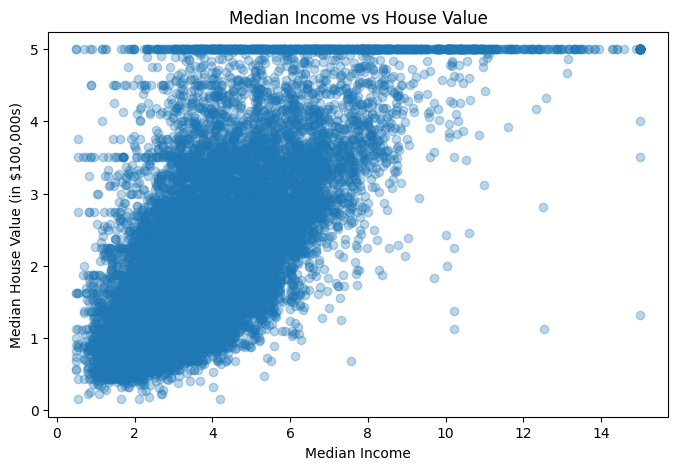

In [6]:
plt.figure(figsize=(8,5))

plt.scatter(X['MedInc'], y, alpha=0.3)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value (in $100,000s)")

plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Data: (16512, 1)
Testing Data: (4128, 1)
Training Records: 16512
Testing Records: 4128


In [8]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

# Display coefficient and intercept
print("Coefficient (Slope):", model.coef_[0])
print("Intercept:", model.intercept_)

Linear Regression Model Trained Successfully!
Coefficient (Slope): 0.4193384939381271
Intercept: 0.4445972916907879


In [9]:
# Predict using test data
y_pred = model.predict(X_test)

# Compare actual and predicted values
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("Actual vs Predicted House Values:")
display(comparison.head(10))

Actual vs Predicted House Values:


,Actual Price,Predicted Price
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


In [10]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("----------------------------")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Model Evaluation Results
----------------------------
Mean Absolute Error (MAE): 0.629908653009376
Mean Squared Error (MSE): 0.7091157771765549
Root Mean Squared Error (RMSE): 0.8420901241414455
R2 Score: 0.45885918903846656


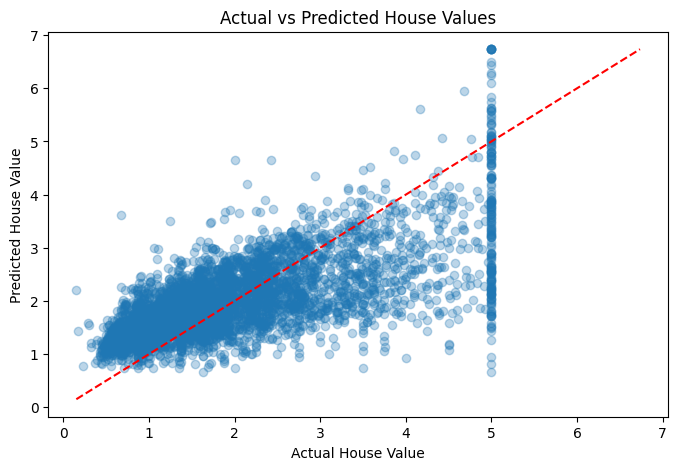

In [11]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.3)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color='red',
    linestyle='--'
)

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")

plt.show()

In [12]:
# New example
new_income = X_train['MedInc'].mean()

# Convert into DataFrame
new_house = pd.DataFrame({
    'MedInc': [new_income]
})

# Predict house value
predicted_price = model.predict(new_house)

print("New House Median Income:", new_income)

print("Predicted House Value ($100,000s):", predicted_price[0])

# Convert into dollars
print("Predicted House Value ($):", predicted_price[0] * 100000)

New House Median Income: 3.88075425750969
Predicted House Value ($100,000s): 2.071946937378876
Predicted House Value ($): 207194.6937378876


In [13]:
df.to_csv("California_Housing_Dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
